In [ ]:
# DON'T FORGET TO RUN THIS!

# general libraries for reading data and making calculations
import numpy as np
import pandas as pd

# library for plotting
import matplotlib as mpl
import matplotlib.pyplot as plt


In [ ]:
# For this analysis, we're going to look at the total gas cost over time. 

# We will visualize as a plot how much Total_Price as a histogram.


In [ ]:
# You need to import the new csv to this file as the files are not connected.
# This then assigns the path of that csv to a dataframe, which is a pandas table
"""df = pd.read_csv('../parent_folder/dataset.csv')"""
# TODO


In [ ]:
# Let's decide how we want to bin our time by calculating the refill frequency.

'''
When we work with plots that have a time scale on one of the axes, we need to ask ourselves how should we visualize that time? 

Do we have data for everyday? Every week? How often does the car get refilled? 

For example, let’s say you have ages and voting trends for the last election but you want to group ages into youth, middle-aged, and senior categories. 
You can group those ages together as bins. Deciding on the right binning size can be hard, but this data should be easy. 
'''

# Let's start by calculating how often the car is refilled. 
# Look back at the mean and averages section in 'data_exploration' for some help.
# I will provide the first line as its a little more complicated.

# Calculate days elapsed since the previous refill
# TODO Change the table name from 'df' to your table name
df['Days_Between_Refills'] = df['Date'].diff().dt.days


#  View statistics on how often the car is usually refilled
# Note, assign these as variables
'''variable = df['Days_Between_Refills'].mean()'''
'''variable = df['Days_Between_Refills'].median()'''
# TODO


# Format and print the two variables
# Hint: Use something called an 'f string literal' to better control outputting variables with text
# Note, the syntax for printing to 1 decimal place is {.1f}
'''print(f"Average time between refills: {variable:.1f} days")''' 
# TODO




NameError: name 'dataset' is not defined

In [ ]:
# What did we learn? 

# The average refill period should close to 12 days. With that knowledge, since we only refill about every two weeks, we should bin by month.

In [ ]:
# Let's bin our data in preparation to plot

# Just run this cell.

df['Date'] = pd.to_datetime(df['Date'])
grouped_table = df.groupby(df['Date'].dt.to_period('M'))['Total_Price'].sum()


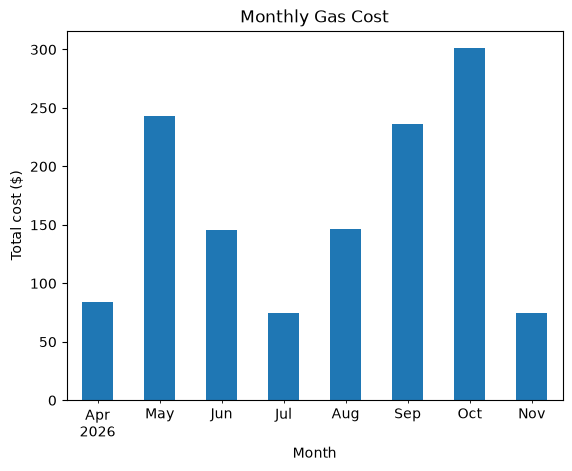

In [ ]:
# Let's plot a bar chart!
'''grouped_table.plot(kind='bar', xlabel='Month', ylabel='Total cost ($)',
                  title='Monthly Gas Cost')'''
# TODO 


plt.show()

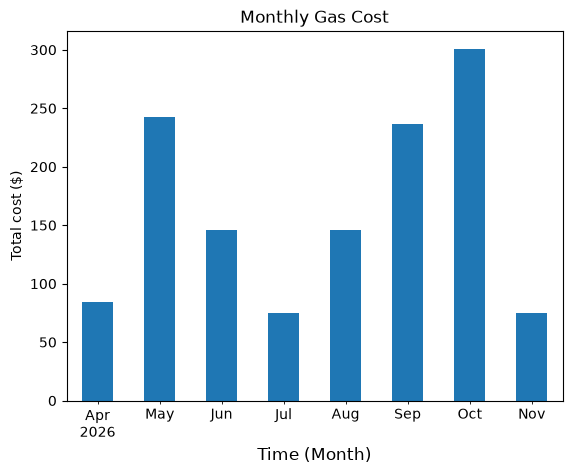

In [ ]:
# Let's tweak the bar plot and change the labels. 

# Setup the matplotlib axes object to access the axes of the bar chart
# Hint: Reuse the code from the previous cell
# Do not forget to change 'grouped_table' name to your table name
'''ax = grouped_table.plot(kind='bar', xlabel='Month', ylabel='Total cost ($)',
                  title='Monthly Gas Cost')'''
# TODO



# Now let's change the X-axis name to 'Time (Month)' instead of 'Month'
'''ax.set_xlabel("New Label", fontsize=12)'''
# TODO


plt.show()

# This logic works for the other axis and title too, like  `ax.set_title("New Title", fontsize=14, fontweight="bold")`


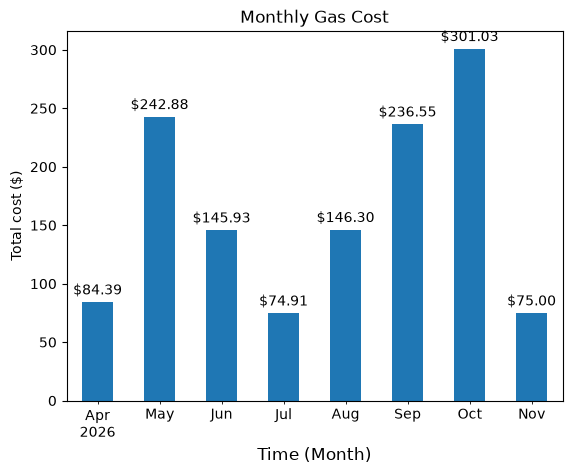

In [ ]:
# Now let's add value labels to the bar chart.

# The axes object does not exist outside of the cell it was defined in, so I've provided your previous work from before. 
# TODO Do not forget to change 'grouped_table' name to your table name
ax = grouped_table.plot(kind='bar', xlabel='Month', ylabel='Total cost ($)',
                  title='Monthly Gas Cost')
ax.set_xlabel("Time (Month)", fontsize=12)
             

# Add bar labels to make the data easier to see.
# TODO


plt.show()

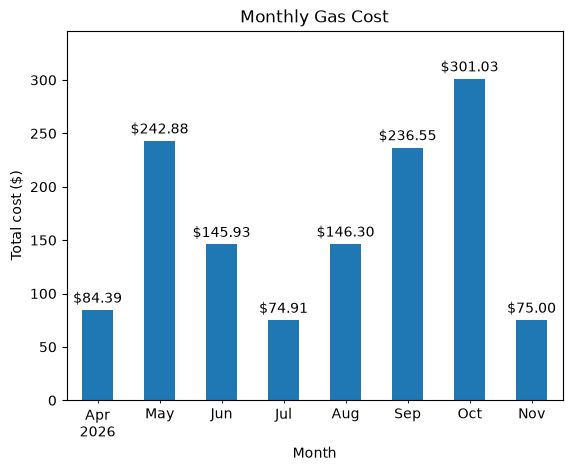

In [ ]:
# Wow, October was an expensive month! 

# You can see that since we added the bar label, it's now overlapping the chart boundary.

# I've copy and pasted your previous code
# TODO Do not forget to change 'grouped_table' name to your table name
ax = grouped_table.plot(kind='bar', xlabel='Month', ylabel='Total cost ($)',
                  title='Monthly Gas Cost')

ax.bar_label(ax.containers[0], fmt='$%.2f', padding=3)


# Let's fix that spacing by increasing the y-axis limit by 15%
'''ax.set_ylim(top=grouped_table.max() * 1.15)'''
# TODO


plt.show()

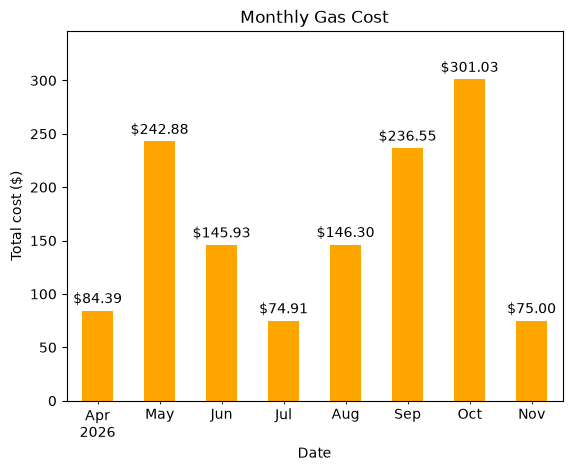

In [ ]:
# Now, change the color of the bar chart.

# I've provided the previous code from the last cell, but change the group_table name to your name

ax = grouped_table.plot(kind='bar', xlabel='Month', ylabel='Total cost ($)',
                  title='Monthly Gas Cost')

ax.bar_label(ax.containers[0], fmt='$%.2f', padding=3)

# Let's fix that spacing by increasing the y-axis limit by 15%
'''ax.set_ylim(top=grouped_table.max() * 1.15)'''

ax.set_ylim(top=grouped_table.max() * 1.15)

# Change the bar color
'''ax = grouped_table.plot(kind='bar', color='red')'''
# TODO


plt.show()


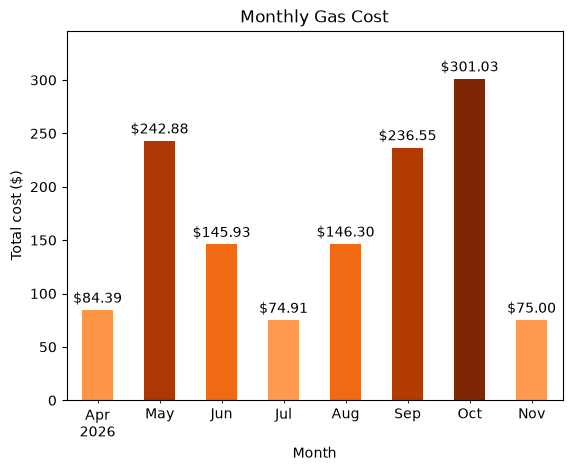

In [ ]:
# Continuing with colors, let's make it so that more expensive months are a darker color.

# we will need to import a colormap library from the matplotlib.colors module
from matplotlib.colors import Normalize


# Now we need to make a color range from lighter to darker shades. Let's do shades of orange.
# This code is more complicated, so I've written it for you. 
# TODO do not forget to change grouped_table name
values = grouped_table.to_numpy() # convers table to a NumPy array
scaled = Normalize(values.min(), values.max())(values) # scales the cost from 0 to 1
colors = plt.cm.Oranges(0.45 + 0.55 * scaled) #assigns an orange value to each value, but range starts at .45 to make all colors darker

# Here is the axes code we were working on 
# TODO Do not forget to change grouped_table name
ax = grouped_table.plot(kind='bar', 
                       color = colors, # Notice that I've changed the 'color' argument to 'colors' which was the range we created
                       xlabel='Month', 
                       ylabel='Total cost ($)',
                  title='Monthly Gas Cost')

ax.bar_label(ax.containers[0], fmt='$%.2f', padding=3)

ax.set_ylim(top=grouped_table.max() * 1.15)

plt.show()

